# Visualize Last-Layer Attention-Graph Layout Evolution and Initialization Robustness

This Visualize notebook presents two complementary last-layer layout analyses for representative constant and chaotic logistic-map sequences at $N = 500$ using Llama-3.2-3B, as presented under **Attention-Induced Token Graphs: Construction and Visualization Robustness** in the appendix.

The layout-evolution figure follows attention-based node positions from a shared token-ordered spiral through 10, 30, 50, and 100 Fruchterman–Reingold (FR) iterations. Because both inputs begin from the same coordinates, their different trajectories reflect input-specific attention weights; most reorganization occurs by 50 iterations, with comparatively minor changes thereafter.

The initialization-robustness figure perturbs the spiral coordinates with Gaussian noise of standard deviation $0.01$, $0.05$, or $0.10$ and compares each initialization with its 100-iteration FR layout. The qualitative organization remains stable across perturbation scales.

The included caches are the `Constant 500` and `Logistic r=4.0` subset of the graph data generated by `Main/Attention-induced-token-graphs/Across-dynamical-complexity/Generate-token-graphs-across-dynamical-complexity.ipynb`.

Import dependencies and define the 500-token analysis window and layout settings.

In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# Analysis window
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS
PROCESSED_DATA_DIR = Path('./processed_graph_data')
FIGURE_OUTPUT_DIR = Path('figure')

NOISY_SPIRAL_DATA_ORDER = (
    'Constant 500',
    'Logistic r=4.0',
)
NOISY_SPIRAL_NOISE_LEVELS = (0.01, 0.05, 0.10)
NOISY_SPIRAL_NOISE_SEED = 42
NOISY_SPIRAL_ITERATION_COUNTS = (0, 100)
NOISY_SPIRAL_SAVE_FILENAME = 'last_layer_noisy_spiral_initialization_simulation_robustness.pdf'
NOISY_SPIRAL_FIGURE_SIZE = (9.4, 10.6)

NOISY_SPIRAL_COLUMN_TITLES = {
    0.01: 'Init perturb. std=0.01',
    0.05: 'Init perturb. std=0.05',
    0.10: 'Init perturb. std=0.10',
}

# FR layout settings used by the main across-dynamical-complexity generation workflow
rgb_graph_layout_seed = 42
rgb_graph_layout_edge_threshold_factor = 0.0

# Edge and node drawing style
RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR = 2.5
RGB_GRAPH_EDGE_BASE_GRAY = 0.15
RGB_GRAPH_EDGE_ALPHA_MIN = 0.06
RGB_GRAPH_EDGE_ALPHA_SPAN = 0.52
RGB_GRAPH_EDGE_ALPHA_GAMMA = 0.85
RGB_GRAPH_EDGE_LW_MIN = 0.35
RGB_GRAPH_EDGE_LW_SPAN = 1.95
RGB_GRAPH_EDGE_LW_GAMMA = 0.90
RGB_GRAPH_NODE_SIZE = 18
RGB_GRAPH_DELIMITER_SIZE = 24
RGB_GRAPH_NODE_SIZE_FLOOR = 8
RGB_GRAPH_DELIMITER_SIZE_FLOOR = 10
RGB_GRAPH_EDGE_STYLE_BINS = 20
RGB_GRAPH_X_MARGIN = 0.01
RGB_GRAPH_Y_MARGIN = 0.06

# Figure layout
DISPLAY_DPI = 150
PDF_DPI = 300
SUBPLOT_ADJUST = dict(left=0.205, right=0.995, bottom=0.085, top=0.940, wspace=0.0, hspace=0.055)
SAVEFIG_PAD_INCHES = 0.03
PANEL_LABEL_FONT_SIZE = 14.7
ROW_LABEL_FONT_SIZE = 14.7
COLUMN_TITLE_Y_OFFSET = 0.014
ROW_LABEL_RIGHT_X = 0.185

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['savefig.dpi'] = PDF_DPI

Define cache names and validation helpers for the two included input archives.

In [2]:
DATA_TITLE_OVERRIDES = {
    'Constant 500': 'Constant sequence',
}

DATA_TITLE_SUFFIXES = {
    'Logistic r=4.0': 'chaotic',
}

# This notebook requires only the cached arrays used by its two figures
REQUIRED_GRAPH_DATA_ARRAY_KEYS = (
    'layer_indices',
    'Wbar',
    'svd_projection_coords',
    'is_delimiter',
)


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f'{title} ({suffix})' if suffix else title


def context_fraction_label(frac):
    # Preserve the generation workflow's context50 label for the 500/1000 analysis fraction
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def graph_data_path(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_graph_data.npz'


# Accept unused generator arrays while requiring every array consumed below
def load_processed_graph_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}

    missing = [key for key in REQUIRED_GRAPH_DATA_ARRAY_KEYS if key not in processed_data]
    if missing:
        raise KeyError(f'{path} is missing required arrays: {missing}')
    return processed_data


# Verify both bundled archives before plotting
def check_processed_graph_data(data_names=NOISY_SPIRAL_DATA_ORDER, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing processed graph data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed graph data:\n' + details)

Define thresholding, coordinate normalization, spiral initialization, FR relaxation, and graph-rendering helpers.

In [3]:
# Express display thresholds relative to the uniform-attention baseline, 1/N
def edge_weight_threshold_from_uniform(n_nodes, factor):
    n_nodes = int(n_nodes)
    if n_nodes <= 0:
        return float('inf')
    return float(factor) / float(n_nodes)


# Center coordinates and scale the largest node radius to one
def _normalize_layout_xy(pos):
    pos = np.asarray(pos, dtype=float)
    if pos.ndim == 1:
        pos = pos[:, None]
    if pos.shape[1] < 2:
        pos = np.column_stack([pos[:, 0], np.zeros(pos.shape[0])])
    pos = pos[:, :2]
    pos = pos - np.mean(pos, axis=0, keepdims=True)
    radius = np.max(np.linalg.norm(pos, axis=1)) if pos.size else 0.0
    if np.isfinite(radius) and radius > 0:
        pos = pos / radius
    return pos


# Map the first three cached hidden-state SVD coordinates independently to RGB
def _minmax_scale_rgb_channels(coords, fill_value=0.5, eps=1e-12):
    coords = np.asarray(coords, dtype=float)
    if coords.ndim == 1:
        coords = coords[:, None]
    if coords.ndim != 2:
        raise ValueError('coords must be 2D (num_tokens x num_components)')

    n = coords.shape[0]
    rgb = np.full((n, 3), float(fill_value), dtype=float)
    if n == 0:
        return rgb

    for k in range(3):
        if coords.shape[1] <= k:
            continue
        col = np.asarray(coords[:, k], dtype=float)
        finite = np.isfinite(col)
        if not np.any(finite):
            continue
        cmin = float(np.min(col[finite]))
        cmax = float(np.max(col[finite]))
        if (cmax - cmin) <= float(eps):
            rgb[finite, k] = float(fill_value)
        else:
            rgb[finite, k] = (col[finite] - cmin) / (cmax - cmin)

    rgb[~np.isfinite(rgb)] = float(fill_value)
    return np.clip(rgb, 0.0, 1.0)


# Place tokens in sequence order along a deterministic outward spiral
def _build_spiral_init_positions(n):
    n = int(n)
    if n <= 0:
        return np.zeros((0, 2), dtype=float)
    if n == 1:
        return np.zeros((1, 2), dtype=float)

    t = np.linspace(0.0, 1.0, n)
    turns = 2.25 if n < 80 else 2.75
    theta = -0.5 * np.pi + 2.0 * np.pi * turns * t
    r = 0.15 + 0.85 * t
    x = r * np.cos(theta)
    y = r * np.sin(theta)
    return _normalize_layout_xy(np.column_stack([x, y]))


# Add reproducible isotropic Gaussian perturbations before renormalizing
def _build_noisy_spiral_init_positions(n, noise_std, seed=NOISY_SPIRAL_NOISE_SEED):
    base_xy = _build_spiral_init_positions(n)
    noise_std = float(noise_std)
    if noise_std <= 0.0:
        return base_xy

    rng = np.random.default_rng(int(seed))
    noisy_xy = base_xy + rng.normal(loc=0.0, scale=noise_std, size=base_xy.shape)
    return _normalize_layout_xy(noisy_xy)


# Relax a supplied initialization with attention weights as FR edge weights
def _build_topological_layout_from_attention_custom_init(
    Wbar,
    init_xy,
    threshold_factor=None,
    spring_iterations=100,
    seed=None,
):
    W = np.asarray(Wbar, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('Wbar must be square')

    n = W.shape[0]
    init_xy = np.asarray(init_xy, dtype=float)
    if init_xy.shape[0] != n:
        raise ValueError('init_xy must have one row per Wbar node')
    init_xy = _normalize_layout_xy(init_xy)

    if n == 0:
        return np.zeros((0, 2), dtype=float)
    if n == 1:
        return np.zeros((1, 2), dtype=float)

    W[~np.isfinite(W)] = 0.0
    W = np.clip(W, a_min=0.0, a_max=None)
    np.fill_diagonal(W, 0.0)

    factor_use = rgb_graph_layout_edge_threshold_factor if threshold_factor is None else float(threshold_factor)
    if factor_use > 0.0:
        layout_threshold = edge_weight_threshold_from_uniform(n, factor=factor_use)
        W[W <= layout_threshold] = 0.0

    n_iter = int(spring_iterations)
    if n_iter <= 0:
        return init_xy

    G = nx.from_numpy_array(W)
    if G.number_of_edges() == 0:
        return init_xy

    seed_use = rgb_graph_layout_seed if seed is None else int(seed)
    pos0 = {i: init_xy[i] for i in range(n)}
    pos_dict = nx.spring_layout(
        G,
        weight='weight',
        seed=seed_use,
        pos=pos0,
        iterations=n_iter,
    )
    return _normalize_layout_xy([pos_dict[i] for i in range(n)])


# Select undirected upper-triangle edges above kappa/N for display
def select_draw_edges(W, threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('W must be square')

    n = W.shape[0]
    if n < 2:
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    iu = np.triu_indices(n, k=1)
    w = W[iu]

    edge_threshold = edge_weight_threshold_from_uniform(n, threshold_factor)
    pos_mask = np.isfinite(w) & (w > edge_threshold)
    if not np.any(pos_mask):
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    chosen = np.nonzero(pos_mask)[0]
    order = np.argsort(w[chosen])[::-1]
    chosen = chosen[order]
    return iu[0][chosen], iu[1][chosen], w[chosen]


# Draw weighted edges, numeric-token circles, and separator-token triangles
def draw_processed_layer_on_ax(
    ax,
    W,
    xy,
    rgb,
    is_delimiter,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
    edge_weight_limits=None,
    node_size_scale=1.0,
):
    W = np.asarray(W, dtype=float)
    xy = np.asarray(xy, dtype=float)
    rgb = np.asarray(rgb, dtype=float)
    is_delimiter = np.asarray(is_delimiter, dtype=bool)

    n = min(W.shape[0], xy.shape[0], rgb.shape[0], is_delimiter.shape[0])
    if n == 0:
        ax.axis('off')
        return {'n': 0, 'edge_count': 0}

    W = W[:n, :n]
    xy = xy[:n]
    rgb = np.clip(rgb[:n], 0.0, 1.0)
    is_delimiter = is_delimiter[:n]
    x = xy[:, 0]
    y = xy[:, 1]
    node_size_scale = float(node_size_scale)

    i_idx, j_idx, w_edges = select_draw_edges(W, threshold_factor=edge_threshold_factor)

    if w_edges.size > 0:
        segments = np.stack([
            np.column_stack([x[i_idx], y[i_idx]]),
            np.column_stack([x[j_idx], y[j_idx]]),
        ], axis=1)

        if edge_weight_limits is None:
            w_min = float(np.min(w_edges))
            w_max = float(np.max(w_edges))
        else:
            w_min, w_max = (float(value) for value in edge_weight_limits)
        w_scaled = np.clip((w_edges - w_min) / (w_max - w_min), 0.0, 1.0) if w_max > w_min else np.ones_like(w_edges)
        n_style_bins = max(1, int(RGB_GRAPH_EDGE_STYLE_BINS))
        bin_indices = np.minimum((w_scaled * n_style_bins).astype(int), n_style_bins - 1)
        bin_centers = (np.arange(n_style_bins, dtype=float) + 0.5) / n_style_bins

        for bin_idx, bin_center in enumerate(bin_centers):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            edge_alpha = RGB_GRAPH_EDGE_ALPHA_MIN + RGB_GRAPH_EDGE_ALPHA_SPAN * (bin_center ** RGB_GRAPH_EDGE_ALPHA_GAMMA)
            edge_lw = RGB_GRAPH_EDGE_LW_MIN + RGB_GRAPH_EDGE_LW_SPAN * (bin_center ** RGB_GRAPH_EDGE_LW_GAMMA)
            edge_rgba = (RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, edge_alpha)
            ax.add_collection(LineCollection(segments[mask], colors=[edge_rgba], linewidths=edge_lw, zorder=2))

    state_mask = ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            x[state_mask],
            y[state_mask],
            c=rgb[state_mask],
            s=max(float(RGB_GRAPH_NODE_SIZE_FLOOR), RGB_GRAPH_NODE_SIZE * 0.8 * node_size_scale),
            alpha=0.95,
            marker='o',
            edgecolors='none',
            zorder=3,
        )

    if np.any(is_delimiter):
        ax.scatter(
            x[is_delimiter],
            y[is_delimiter],
            c=rgb[is_delimiter],
            s=max(float(RGB_GRAPH_DELIMITER_SIZE_FLOOR), RGB_GRAPH_DELIMITER_SIZE * 0.8 * node_size_scale),
            alpha=0.95,
            marker='^',
            edgecolors='none',
            zorder=4,
        )

    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.margins(x=RGB_GRAPH_X_MARGIN, y=RGB_GRAPH_Y_MARGIN)
    return {'n': int(n), 'edge_count': int(w_edges.size)}

Load final-layer graph and hidden-state data, rerun FR layouts from perturbed spirals, and assemble the initialization-robustness figure.

In [ ]:
def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = ', '.join(str(int(layer)) for layer in layer_indices) if layer_indices.size else 'none'
        raise ValueError(f'Layer {layer_index} is unavailable. Available one-based layers: {available}')
    return int(matches[0])


def available_layer_indices(data_name=NOISY_SPIRAL_DATA_ORDER[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
    return np.asarray(processed_data['layer_indices'], dtype=int)


def noisy_spiral_row_specs(data_names=NOISY_SPIRAL_DATA_ORDER, iteration_counts=NOISY_SPIRAL_ITERATION_COUNTS):
    if tuple(int(x) for x in iteration_counts) != (0, 100):
        raise ValueError('This figure expects iteration_counts=(0, 100).')

    specs = []
    for data_name in data_names:
        specs.append((data_name, 0, f'{panel_title(data_name)}\nAt initialization'))
        specs.append((data_name, 100, f'{panel_title(data_name)}\nAfter FR spring layout'))
    return specs


def collect_last_layer_noisy_spiral_panel_data(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=NOISY_SPIRAL_DATA_ORDER,
    noise_levels=NOISY_SPIRAL_NOISE_LEVELS,
    iteration_counts=NOISY_SPIRAL_ITERATION_COUNTS,
    data_dir=PROCESSED_DATA_DIR,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    layer_index = int(layer_index)
    panel_data = {}
    all_edge_weights = []

    for data_name in data_names:
        processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        offset = layer_offset(processed_data, layer_index)

        # Wbar is the mean of symmetrized per-head attention
        Wbar = np.asarray(processed_data['Wbar'], dtype=np.float32)[offset]
        svd_projection_coords = np.asarray(processed_data['svd_projection_coords'], dtype=np.float32)[offset]
        rgb_colors = _minmax_scale_rgb_channels(svd_projection_coords).astype(np.float32)
        is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)

        _, _, w_edges = select_draw_edges(Wbar, threshold_factor=edge_threshold_factor)
        if w_edges.size:
            all_edge_weights.append(w_edges)

        # Hold the attention graph fixed while varying only the initial coordinates
        for noise_std in noise_levels:
            noise_std = float(noise_std)
            init_xy = _build_noisy_spiral_init_positions(Wbar.shape[0], noise_std=noise_std)
            for iteration_count in iteration_counts:
                iteration_count = int(iteration_count)
                if iteration_count < 0:
                    raise ValueError('iteration_counts must be nonnegative')
                layout_positions = _build_topological_layout_from_attention_custom_init(
                    Wbar,
                    init_xy=init_xy,
                    threshold_factor=rgb_graph_layout_edge_threshold_factor,
                    spring_iterations=iteration_count,
                ).astype(np.float32)
                panel_data[(data_name, iteration_count, noise_std)] = dict(
                    data_name=data_name,
                    noise_std=noise_std,
                    iteration_count=iteration_count,
                    Wbar=Wbar,
                    layout_positions=layout_positions,
                    rgb_colors=rgb_colors,
                    is_delimiter=is_delimiter,
                )

    # Use one edge-weight scale across all panels in the figure
    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)

    return panel_data, edge_weight_limits


def add_noisy_spiral_grid_labels(fig, axes, row_specs, noise_levels):
    fig.canvas.draw()

    top_y = axes[0, 0].get_position().y1
    for col, noise_std in enumerate(noise_levels):
        noise_std = float(noise_std)
        pos = axes[0, col].get_position()
        fig.text(
            pos.x0 + 0.5 * pos.width,
            top_y + COLUMN_TITLE_Y_OFFSET,
            NOISY_SPIRAL_COLUMN_TITLES.get(noise_std, f'Init perturb. std={noise_std:g}'),
            ha='center',
            va='bottom',
            fontsize=PANEL_LABEL_FONT_SIZE,
        )

    for row, (_, _, row_label) in enumerate(row_specs):
        pos = axes[row, 0].get_position()
        fig.text(
            ROW_LABEL_RIGHT_X,
            pos.y0 + 0.5 * pos.height,
            row_label,
            ha='right',
            va='center',
            fontsize=ROW_LABEL_FONT_SIZE,
            linespacing=1.12,
        )


def add_last_layer_graph_figure_key(
    fig,
    bbox_to_anchor=(0.58, 0.035),
    fontsize=9.6,
    handlelength=1.15,
    handletextpad=0.16,
    columnspacing=2,
    mode=None,
):
    marker_handles = [
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=6.4
        ),
        Line2D(
            [0], [0], marker='^', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=7.0
        ),
        Line2D(
            [0, 1], [0, 0], color='#444444', linewidth=2.2, alpha=0.80
        ),
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='#7B6FC8',
            markeredgecolor='none', markersize=7.0
        ),
    ]
    marker_labels = [
        'Numeric-token nodes',
        'Separator-token nodes',
        ' Attention-weighted edges',
        'Token hidden-state signal',
    ]
    legend_kwargs = dict(
        handles=marker_handles,
        labels=marker_labels,
        loc='lower center',
        bbox_to_anchor=bbox_to_anchor,
        ncol=4,
        frameon=True,
        fontsize=fontsize,
        handlelength=handlelength,
        handletextpad=handletextpad,
        columnspacing=columnspacing,
        borderaxespad=0.0,
    )
    if mode is not None:
        legend_kwargs['mode'] = mode
    fig.legend(**legend_kwargs)


def plot_last_layer_noisy_spiral_initialization_simulation_robustness(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=NOISY_SPIRAL_DATA_ORDER,
    noise_levels=NOISY_SPIRAL_NOISE_LEVELS,
    iteration_counts=NOISY_SPIRAL_ITERATION_COUNTS,
    data_dir=PROCESSED_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=True,
    save_filename=NOISY_SPIRAL_SAVE_FILENAME,
    show=True,
):
    layer_index = int(layer_index)
    if layer_index < 1:
        raise ValueError('Use one-based layer indices.')

    data_names = tuple(data_names)
    noise_levels = tuple(float(noise_std) for noise_std in noise_levels)
    iteration_counts = tuple(int(iteration_count) for iteration_count in iteration_counts)
    row_specs = noisy_spiral_row_specs(data_names=data_names, iteration_counts=iteration_counts)
    panel_data, edge_weight_limits = collect_last_layer_noisy_spiral_panel_data(
        layer_index=layer_index,
        frac=frac,
        data_names=data_names,
        noise_levels=noise_levels,
        iteration_counts=iteration_counts,
        data_dir=data_dir,
    )

    fig, axes = plt.subplots(
        len(row_specs),
        len(noise_levels),
        figsize=NOISY_SPIRAL_FIGURE_SIZE,
        dpi=DISPLAY_DPI,
        squeeze=False,
    )

    for row, (data_name, iteration_count, _) in enumerate(row_specs):
        for col, noise_std in enumerate(noise_levels):
            payload = panel_data[(data_name, int(iteration_count), float(noise_std))]
            draw_processed_layer_on_ax(
                axes[row, col],
                payload['Wbar'],
                payload['layout_positions'],
                payload['rgb_colors'],
                payload['is_delimiter'],
                edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
                edge_weight_limits=edge_weight_limits,
            )

    fig.subplots_adjust(**SUBPLOT_ADJUST)
    add_noisy_spiral_grid_labels(fig, axes, row_specs, noise_levels)
    add_last_layer_graph_figure_key(
        fig,
        bbox_to_anchor=(-0.04, 0.040, 1.04, 0.045),
        fontsize=12.1,
        handlelength=1.0,
        handletextpad=0.18,
        mode='expand',
    )
    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_output_dir / str(save_filename), bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=PDF_DPI)

    if show:
        plt.show()

    return fig

## FR layout evolution

Follow the final-layer graph from the shared token-ordered spiral through 10, 30, 50, and 100 FR iterations. An ellipsis separates the closely spaced early trajectory from the final 100-iteration layout used by subsequent token-graph visualizations.

In [5]:
# Iteration checkpoints and layout settings for the evolution figure
SPIRAL_NO_NOISE_ITERATION_COUNTS = (0, 10, 30, 50, 100)
SPIRAL_NO_NOISE_ELLIPSIS_COLUMN = 'ellipsis'
SPIRAL_NO_NOISE_SAVE_FILENAME = 'last_layer_FR_iteration_trajectory.pdf'
SPIRAL_NO_NOISE_FIGURE_SIZE = (11.8, 4.2)
SPIRAL_NO_NOISE_SUBPLOT_ADJUST = dict(left=0.165, right=0.995, bottom=0.145, top=0.900, wspace=0.010, hspace=0.025)
SPIRAL_NO_NOISE_COLUMN_TITLE_Y_OFFSET = 0.012
SPIRAL_NO_NOISE_ROW_LABEL_FONT_SIZE = 11.5
SPIRAL_NO_NOISE_COLUMN_TITLE_FONT_SIZE = SPIRAL_NO_NOISE_ROW_LABEL_FONT_SIZE
SPIRAL_NO_NOISE_COLUMN_TITLES = {
    0: 'Initialization',
    10: 'After 10 FR iterations',
    30: 'After 30 FR iterations',
    50: 'After 50 FR iterations',
    100: 'After 100 FR iterations',
}
SPIRAL_NO_NOISE_NODE_SIZE_SCALE = 0.55
SPIRAL_NO_NOISE_ELLIPSIS_FONT_SIZE = 18.0
SPIRAL_NO_NOISE_ELLIPSIS_WIDTH_RATIO = 0.28
SPIRAL_NO_NOISE_ROW_LABEL_RIGHT_X = 0.150


def collect_last_layer_spiral_no_noise_iteration_panel_data(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=NOISY_SPIRAL_DATA_ORDER,
    iteration_counts=SPIRAL_NO_NOISE_ITERATION_COUNTS,
    data_dir=PROCESSED_DATA_DIR,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    layer_index = int(layer_index)
    panel_data = {}
    all_edge_weights = []

    for data_name in data_names:
        processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        offset = layer_offset(processed_data, layer_index)

        # Wbar is the mass-weighted mean of symmetrized per-head attention
        # (equivalent to uniform head weighting for the dense attention used here)
        Wbar = np.asarray(processed_data['Wbar'], dtype=np.float32)[offset]
        svd_projection_coords = np.asarray(processed_data['svd_projection_coords'], dtype=np.float32)[offset]
        rgb_colors = _minmax_scale_rgb_channels(svd_projection_coords).astype(np.float32)
        is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)
        init_xy = _build_spiral_init_positions(Wbar.shape[0])

        _, _, w_edges = select_draw_edges(Wbar, threshold_factor=edge_threshold_factor)
        if w_edges.size:
            all_edge_weights.append(w_edges)

        # Reuse the same noiseless spiral so changes across columns show FR evolution
        for iteration_count in iteration_counts:
            iteration_count = int(iteration_count)
            if iteration_count < 0:
                raise ValueError('iteration_counts must be nonnegative')
            layout_positions = _build_topological_layout_from_attention_custom_init(
                Wbar,
                init_xy=init_xy,
                threshold_factor=rgb_graph_layout_edge_threshold_factor,
                spring_iterations=iteration_count,
            ).astype(np.float32)
            panel_data[(data_name, iteration_count)] = dict(
                data_name=data_name,
                iteration_count=iteration_count,
                Wbar=Wbar,
                layout_positions=layout_positions,
                rgb_colors=rgb_colors,
                is_delimiter=is_delimiter,
            )

    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)

    return panel_data, edge_weight_limits


def spiral_no_noise_display_columns(iteration_counts):
    iteration_counts = tuple(int(iteration_count) for iteration_count in iteration_counts)
    if len(iteration_counts) >= 2 and iteration_counts[-1] > iteration_counts[-2] + 10:
        return iteration_counts[:-1] + (SPIRAL_NO_NOISE_ELLIPSIS_COLUMN, iteration_counts[-1])
    return iteration_counts


def add_spiral_no_noise_iteration_grid_labels(fig, axes, data_names, display_columns):
    fig.canvas.draw()

    top_y = axes[0, 0].get_position().y1
    for col, display_column in enumerate(display_columns):
        if display_column == SPIRAL_NO_NOISE_ELLIPSIS_COLUMN:
            continue
        pos = axes[0, col].get_position()
        fig.text(
            pos.x0 + 0.5 * pos.width,
            top_y + SPIRAL_NO_NOISE_COLUMN_TITLE_Y_OFFSET,
            SPIRAL_NO_NOISE_COLUMN_TITLES.get(int(display_column), f'{int(display_column)} FR iterations'),
            ha='center',
            va='bottom',
            fontsize=SPIRAL_NO_NOISE_COLUMN_TITLE_FONT_SIZE,
        )

    for row, data_name in enumerate(data_names):
        pos = axes[row, 0].get_position()
        fig.text(
            SPIRAL_NO_NOISE_ROW_LABEL_RIGHT_X,
            pos.y0 + 0.5 * pos.height,
            panel_title(data_name),
            ha='right',
            va='center',
            fontsize=SPIRAL_NO_NOISE_ROW_LABEL_FONT_SIZE,
        )


def plot_last_layer_spiral_no_noise_iteration_trajectory(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=NOISY_SPIRAL_DATA_ORDER,
    iteration_counts=SPIRAL_NO_NOISE_ITERATION_COUNTS,
    data_dir=PROCESSED_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=True,
    save_filename=SPIRAL_NO_NOISE_SAVE_FILENAME,
    show=True,
):
    layer_index = int(layer_index)
    if layer_index < 1:
        raise ValueError('Use one-based layer indices.')

    data_names = tuple(data_names)
    iteration_counts = tuple(int(iteration_count) for iteration_count in iteration_counts)
    display_columns = spiral_no_noise_display_columns(iteration_counts)
    width_ratios = [
        SPIRAL_NO_NOISE_ELLIPSIS_WIDTH_RATIO if display_column == SPIRAL_NO_NOISE_ELLIPSIS_COLUMN else 1.0
        for display_column in display_columns
    ]
    panel_data, edge_weight_limits = collect_last_layer_spiral_no_noise_iteration_panel_data(
        layer_index=layer_index,
        frac=frac,
        data_names=data_names,
        iteration_counts=iteration_counts,
        data_dir=data_dir,
    )

    fig, axes = plt.subplots(
        len(data_names),
        len(display_columns),
        figsize=SPIRAL_NO_NOISE_FIGURE_SIZE,
        dpi=DISPLAY_DPI,
        squeeze=False,
        gridspec_kw={'width_ratios': width_ratios},
    )

    for row, data_name in enumerate(data_names):
        for col, display_column in enumerate(display_columns):
            ax = axes[row, col]
            if display_column == SPIRAL_NO_NOISE_ELLIPSIS_COLUMN:
                ax.axis('off')
                ax.text(
                    0.5,
                    0.5,
                    '...',
                    transform=ax.transAxes,
                    ha='center',
                    va='center',
                    fontsize=SPIRAL_NO_NOISE_ELLIPSIS_FONT_SIZE,
                    color='0.35',
                )
                continue

            payload = panel_data[(data_name, int(display_column))]
            draw_processed_layer_on_ax(
                ax,
                payload['Wbar'],
                payload['layout_positions'],
                payload['rgb_colors'],
                payload['is_delimiter'],
                edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
                edge_weight_limits=edge_weight_limits,
                node_size_scale=SPIRAL_NO_NOISE_NODE_SIZE_SCALE,
            )

    fig.subplots_adjust(**SPIRAL_NO_NOISE_SUBPLOT_ADJUST)
    add_spiral_no_noise_iteration_grid_labels(fig, axes, data_names, display_columns)
    add_last_layer_graph_figure_key(
        fig,
        bbox_to_anchor=(0.58, 0.050),
        fontsize=10.56,
        columnspacing=4,
    )
    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_output_dir / str(save_filename), bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=PDF_DPI)

    if show:
        plt.show()

    return fig


Validate the included caches, select the final available layer, display the FR evolution, and save its PDF.

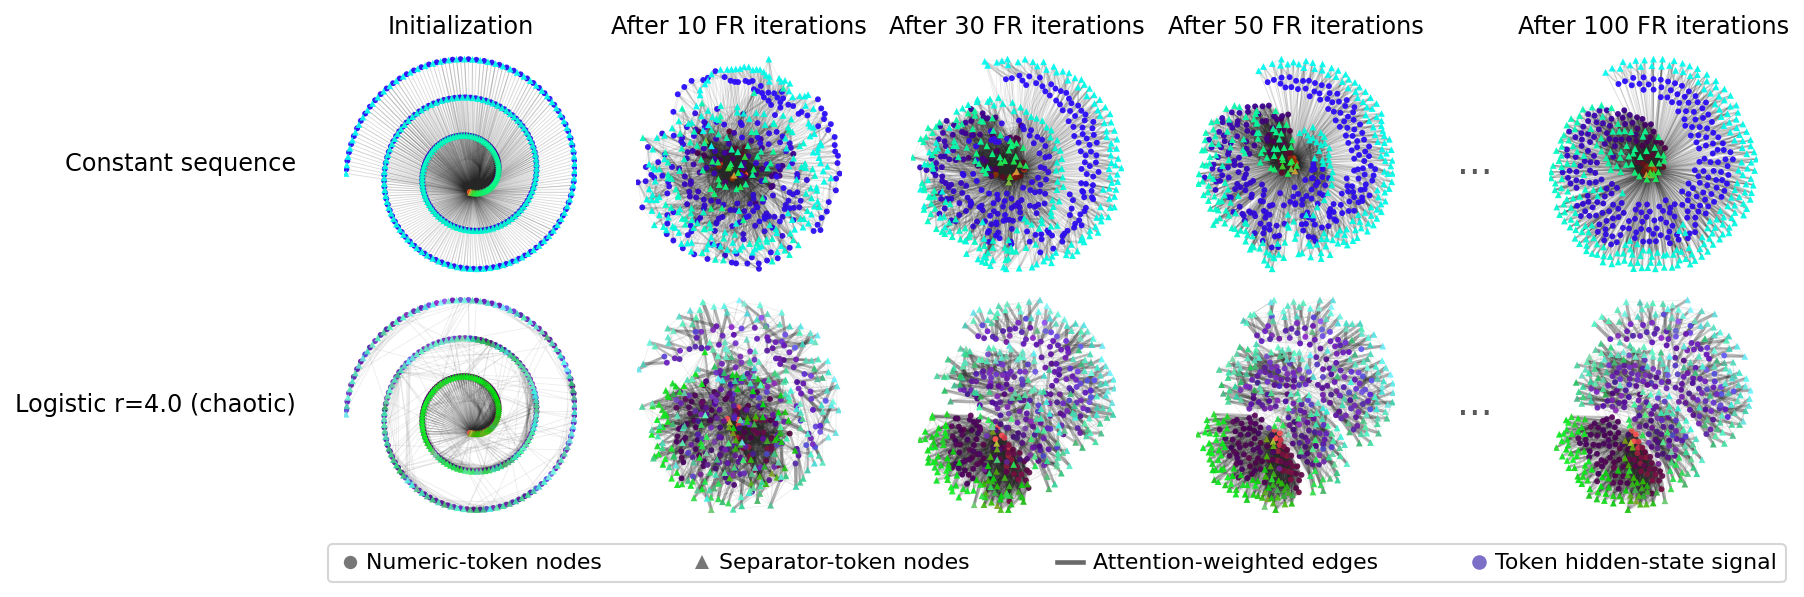

In [6]:
# The included caches contain the constant and chaotic logistic examples
check_processed_graph_data(data_names=NOISY_SPIRAL_DATA_ORDER)
LAYER_INDEX = int(available_layer_indices(data_name=NOISY_SPIRAL_DATA_ORDER[0])[-1])

plot_last_layer_spiral_no_noise_iteration_trajectory(
    layer_index=LAYER_INDEX,
    frac=CONTEXT_FRAC,
    data_names=NOISY_SPIRAL_DATA_ORDER,
    iteration_counts=SPIRAL_NO_NOISE_ITERATION_COUNTS,
    save=True,
    show=True,
);

Validate the included caches, display the noisy-initialization comparison, and save its PDF.

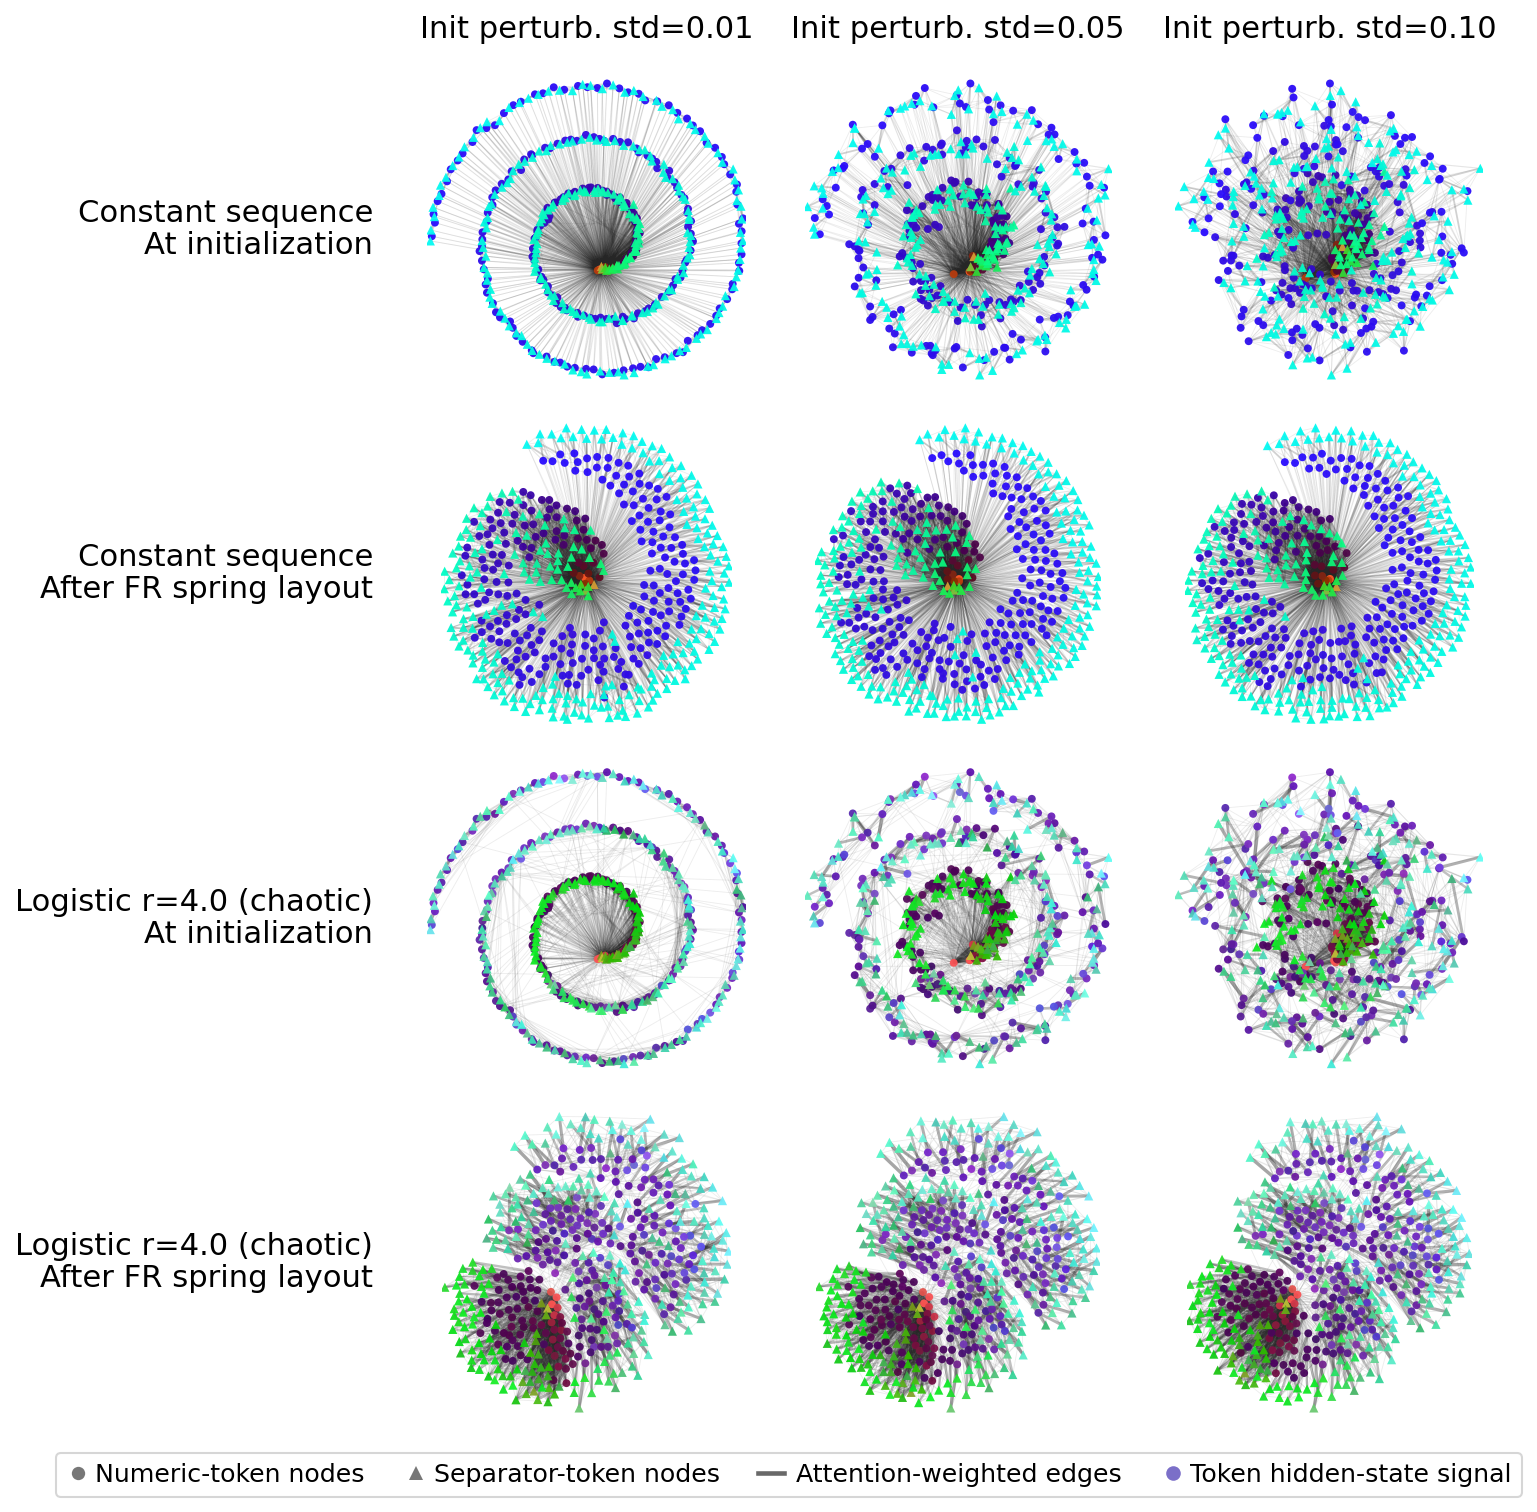

In [7]:
check_processed_graph_data(data_names=NOISY_SPIRAL_DATA_ORDER)
LAYER_INDEX = int(available_layer_indices(data_name=NOISY_SPIRAL_DATA_ORDER[0])[-1])

plot_last_layer_noisy_spiral_initialization_simulation_robustness(
    layer_index=LAYER_INDEX,
    frac=CONTEXT_FRAC,
    data_names=NOISY_SPIRAL_DATA_ORDER,
    noise_levels=NOISY_SPIRAL_NOISE_LEVELS,
    iteration_counts=NOISY_SPIRAL_ITERATION_COUNTS,
    save=True,
    show=True,
);